# Двухступенчатая свободная турбина на взлётном режиме

Расчёт для ЛМС-901 «Байкал». По заданной мощности после редуктора определяем расход газа и средний диаметр, рассчитываем две ступени, затем по состоянию газа за вторым колесом находим скорость и площадь выходного сопла.

[1. Исходные данные](#inputs) · [2. Цикл и расход](#cycle) · [3. Диаметр и число ступеней](#size) · [4. Обе ступени и мощность](#stages) · **[5. Выходное сопло](#nozzle)** · [6. Треугольники и профили](#span) · [Дополнительные варианты](#variants) · [Словарь переменных](#symbols)

**Сечения.** В каждой ступени 0 — вход в сопловой аппарат (СА), 1 — выход из СА и вход в рабочее колесо (РК), 2 — выход из РК. В выпускном устройстве 5 — сразу за РК второй ступени, 9 — срез сопла. Звёздочка означает полный параметр, индекс $s$ — изоэнтропическое состояние. Давления абсолютные.

**Как читать.** Основной порядок — исходные данные, цикл, геометрия, две ступени и проверка мощности в § 4.4. Над каждым расчётным шагом записаны формулы. Таблицы и графики уже выведены. После изменения исходных данных выполните **Run All**. Все вычисления в СИ, единицы вывода указаны в таблицах. Достаточно Python 3 с NumPy, pandas и Matplotlib в Jupyter.

<a id="inputs"></a>
## 1. Исходные данные

В исходной точке $\pi_к^*=10$. Полная температура 1440 К задана в горле СА турбины высокого давления (ТВД) после возврата охлаждающего воздуха. ТВД приводит компрессор. Следующая за ней свободная турбина (СТ) передаёт мощность через редуктор.

Два коэффициента задают разные граничные условия. $r_p=p_н/p_5$ задаёт **статическое** противодавление ступени. $\sigma_с=p_9^*/p_5^*$ описывает потерю **полного** давления на участке от РК2 до среза.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.precision", 5)

In [2]:
# Цикл и режим
N_req = 750_000  # Заданная мощность после редуктора, Вт
pi_design = 10.0  # Проектная степень повышения полного давления компрессора
n = 30_000  # Частота вращения свободной турбины, об/мин
Ta = 288.0  # Температура наружного воздуха, К
pa = 101_300.0  # Статическое давление атмосферы, Па
R = 287.4  # Удельная газовая постоянная модели, Дж/(кг·К)
sigma_in = 0.98  # Сохранение полного давления во входном устройстве
eta_poly = 0.83  # Политропический КПД компрессора
sigma_burn = 0.97  # Сохранение полного давления в камере сгорания
eta_burn = 0.995  # Коэффициент полноты сгорания
Qfuel = 43e6  # Низшая теплота сгорания топлива, Дж/кг
l0 = 14.61  # Стехиометрическая масса воздуха на 1 кг топлива, кг/кг
leak = 0.007  # Безвозвратные утечки в долях расхода воздуха компрессора
cool = 0.05  # Отбор на охлаждение в долях расхода воздуха компрессора
T4t = 1440.0  # Полная температура смеси в горле СА ТВД, К
eta_hpt = 0.90  # КПД ТВД по полным параметрам
eta_mech = 0.995  # Механический КПД в балансе каждого вала
eta_gear = 0.99  # КПД редуктора

In [3]:
# Предварительная СТ и выпуск
eta_pre = 0.91  # Лопаточный КПД в предварительном цикле
c_pre = 210.0  # Заданная скорость за СТ в предварительном расчёте, м/с
rp = 0.995  # Отношение статических давлений атмосферы и газа за РК2
sigma_nozzle = 0.995  # Отношение полных давлений на срезе и за РК2
height_ratio = 1/5  # Отношение выходной высоты лопатки к среднему диаметру
y0 = 0.57  # Отношение скоростей для оценки числа ступеней
mu = 1.0  # Коэффициент использования выходной скорости
c_mean = 180.0  # Принятая средняя выходная скорость за ступенью для оценки числа ступеней, м/с

In [4]:
# Венцы и профили
reaction_I = 0.350  # Заданная реактивность I ступени на среднем радиусе
reaction_II = 0.415  # Заданная реактивность II ступени на среднем радиусе
angle1_I = 18.0  # Угол абсолютной скорости за СА1 от направления вращения, °
angle1_II = 24.5  # Угол абсолютной скорости за СА2 от направления вращения, °
angle2_I = 90.0  # Угол абсолютной скорости за РК1 от направления против вращения, °
phi_I = 0.96  # Коэффициент скорости соплового аппарата I ступени
phi_II = 0.96  # Коэффициент скорости соплового аппарата II ступени
psi_I = 0.9704670965605235  # Коэффициент скорости РК I ступени, подбор в исходной точке
psi_II = 0.9704670965605235  # Коэффициент скорости РК II ступени, подбор в исходной точке
gap = 0.0003  # Радиальный зазор обоих РК, м
thickness = 0.10  # Относительная максимальная толщина профиля
pitch_ratio = 0.82  # Заданный относительный шаг на среднем радиусе

In [5]:
# Параметры дополнительных вариантов
c_target = 200.0  # Заданная скорость для обратного расчёта сопла, м/с
stress_limit = 320.0  # Принятое предельное напряжение в эмпирической оценке, МПа
kn = 6.8e-6  # Коэффициент эмпирической формулы напряжения, МПа/[м²·(об/мин)²]
takeoff_min = 5.0  # Продолжительность взлётного режима для оценки массы топлива, мин
Kscheme = 0.8  # Поправка на схему двигателя в формуле массы
Kresource = 1.0  # Поправка на ресурс двигателя в формуле массы

<a id="cycle"></a>
## 2. Цикл и расход газа

### Свойства рабочего тела

На участке расширения или сжатия используем $c_p$ при представительной температуре и $k=c_p/(c_p-R)$. Для смешения энтальпия отсчитывается от 288 К по средней теплоёмкости из Mathcad

$$h(T)=c_{pm}(T)T-c_{pm}(288)\cdot288.$$

Зависимости теплоёмкостей и границы их применения приведены [в приложении](#properties). Две функции в следующей ячейке считают истинную и среднюю теплоёмкости. Для воздуха достаточно передать температуру. При расчёте газа вторым аргументом передаём коэффициент избытка воздуха. В формулах приложения для чистого воздуха слагаемые с $1/\alpha$ исчезают.

In [6]:
def cp_true(T, alpha=math.inf):
    """Истинная теплоёмкость при T, Дж/(кг·К). По умолчанию — воздух."""
    if alpha <= 0.2:
        raise ValueError("Для полинома нужна величина α > 0,2.")
    if T < 750:
        A = 0.0025 * T - 0.875
        B = 0.000025 * T**2 - 0.0275 * T + 6.5625
        value = 0.2407 + 0.0174/alpha
        value += (0.0193 + 0.0093/alpha) * A
        value += (0.002 - 0.001056/(alpha-0.2)) * B
    else:
        C = 0.001176 * T - 0.88235
        E = 0.0000055556 * T**2 - 0.013056 * T + 6.67
        value = 0.26 + 0.0267/alpha
        value += (0.032 + 0.0133/alpha) * C
        value -= (0.00374 + 0.0094/(alpha**2+10)) * E
    return 4187 * value

def cp_mean(T, alpha=math.inf):
    """Средняя теплоёмкость для вычисления энтальпии, Дж/(кг·К)."""
    if T < 700:
        value = 0.236 + (1.2 + 2.25/alpha) * 1e-5 * (T-70)
    else:
        value = 0.218 + (2.2 + 1.25/alpha) * 1e-5 * (T+450)
    return 4187 * value

### Компрессор

Сначала определяем адиабатический КПД по политропическому, затем полные температуру и давление за компрессором и работу на килограмм воздуха. Начальное $k=1{,}4$ уточняем дважды по $c_p((T_н+T_к^*)/2)$.

$$e=(k-1)/k,\qquad \eta_к=\frac{(\pi_к^*)^e-1}{(\pi_к^*)^{e/\eta_{пол}}-1},\qquad
T_к^*=T_н\left(1+\frac{(\pi_к^*)^e-1}{\eta_к}\right).$$

$$p_к^*=\sigma_{вх}p_н\pi_к^*,\qquad L_к=c_{pв}(T_к^*-T_н).$$
    
Один и тот же расчёт выполняем для нескольких степеней сжатия. Строка `cycle_data[pi_k]` хранит параметры одного варианта. Проектный вариант выбирает переменная `pi_design`. В приложении эти же строки используются для графиков.

In [7]:
pi_values = [7, 8, 9, 10, 11]
if pi_design in pi_values:
    pi_values.remove(pi_design)
pi_values.append(pi_design)  # Проектный вариант считаем последним.
cycle_data = {}

for pi_k in pi_values:
    if pi_k <= 1:
        raise ValueError("Степень сжатия должна превышать единицу.")
    k = 1.4
    for _ in range(3):
        e = (k - 1) / k
        eta_k = (pi_k**e - 1) / (pi_k**(e/eta_poly) - 1)
        Tk = Ta * (1 + (pi_k**e - 1)/eta_k)
        cp = cp_true((Ta + Tk)/2)
        k = cp / (cp - R)
    pk = sigma_in * pa * pi_k
    Lk = cp * (Tk - Ta)
    cycle_data[pi_k] = dict(Tk=Tk, pk=pk, Lk=Lk)

design = cycle_data[pi_design]
print(f"За компрессором: {design['Tk']:.2f} К, {design['pk']/1000:.2f} кПа. Работа {design['Lk']/1000:.3f} кДж/кг.")

За компрессором: 627.88 К, 992.74 кПа. Работа 347.702 кДж/кг.


### Топливо, охлаждение и турбина высокого давления

Рассмотрим 1 кг воздуха на входе. В КС идёт $1-g_{ут}-g_{охл}$, на охлаждение ТВД — $g_{охл}$. Охлаждающий воздух возвращается к сечению с заданными 1440 К. Поэтому масса газа после смешения $m_г=1-g_{ут}+f$. Доля топлива $f$ отнесена ко всему воздуху компрессора.

$$f=\frac{(1-g_{ут})[h_г(\alpha,T_4^*)-h_в(T_к^*)]}{\eta_г Q_н-h_г(\alpha,T_4^*)},\qquad
\alpha=\frac{1-g_{ут}}{f l_0},\qquad L_{ТВД}=\frac{L_к}{m_г\eta_м}.$$

$$T_{СТ,вх}^*=T_4^*-\frac{L_{ТВД}}{c_p},\qquad
p_{СТ,вх}^*=\sigma_{кс}p_к^*\left(1-\frac{L_{ТВД}}{\eta_{ТВД}c_p T_4^*}\right)^{c_p/R}.$$

Два прохода по составу и три по температуре ТВД воспроизводят порядок уточнений в исходном расчёте.

In [8]:
for case in cycle_data.values():
    Tk = case["Tk"]
    h_air = cp_mean(Tk)*Tk - cp_mean(288)*288
    alpha = 1 / (0.025*l0)
    for _ in range(2):
        hmix = cp_mean(T4t, alpha)*T4t - cp_mean(288, alpha)*288
        f = (1 - leak) * (hmix - h_air) / (eta_burn*Qfuel - hmix)
        alpha = (1 - leak) / (f*l0)
    mg = 1 - leak + f
    Lh = case["Lk"] / (mg*eta_mech)

    cp = cp_true(T4t, alpha)
    for _ in range(3):
        cp_hpt = cp
        Tin = T4t - Lh/cp
        base = 1 - Lh/(eta_hpt*cp*T4t)
        if base <= 0:
            raise ValueError("Проверьте располагаемый перепад ТВД.")
        pin = sigma_burn * case["pk"] * base**(cp/R)
        cp = cp_true((T4t + Tin)/2, alpha)
    case.update(f=f, mg=mg, alpha=alpha, Tin=Tin, pin=pin, cp_hpt=cp_hpt)

print(f"Перед СТ: {design['Tin']:.2f} К, {design['pin']/1000:.3f} кПа. Избыток воздуха α = {design['alpha']:.4f}.")

Перед СТ: 1163.27 К, 340.900 кПа. Избыток воздуха α = 2.9134.


### Предварительный расчёт СТ

Перепад считается от **полного** состояния перед СТ до **статического** давления за РК2. Скорость $c_{пред}=210$ м/с задаёт выходную кинетическую энергию на этом шаге. Расход определяем по заданной мощности $N_{зад}$.

$$p_5=p_н/r_p,\qquad H_{СТ}=c_p T_{СТ,вх}^*\left[1-(p_5/p_{СТ,вх}^*)^{R/c_p}\right],\qquad
L_{СТ}=\eta_{лоп,пред}H_{СТ}-c_{пред}^2/2.$$

$$T_{5,пред}=T_{СТ,вх}^*-\eta_{лоп,пред} H_{СТ}/c_p,\quad
G_{г,пред}=\frac{N_{зад}}{L_{СТ}\eta_м\eta_р},\quad G_в=G_г/m_г,\quad G_т=fG_в.$$

**Расход для проектирования.** Цикл даёт предварительное значение $G_{г,пред}$. На взлётном режиме принимаем расход с шагом 0,001 кг/с, округляя вверх. С принятым $G_г$ пересчитываются расход воздуха и топлива, диаметры, обе ступени и выпускное сопло. Требуемые 750 кВт задают нижнюю границу мощности после редуктора. Достигнутую мощность проверяем отдельно по результатам ступеней в § 4.4.

In [9]:
p5 = pa / rp
for case in cycle_data.values():
    Tin, pin, alpha = case["Tin"], case["pin"], case["alpha"]
    if pin <= p5:
        raise ValueError("Для расширения в СТ полное давление на входе должно превышать p5.")
    cp = case["cp_hpt"]
    for _ in range(3):
        cp_pt = cp
        Hpt = cp * Tin * (1 - (p5/pin)**(R/cp))
        Lpt = eta_pre * Hpt - c_pre**2/2
        Tpre = Tin - eta_pre*Hpt/cp
        cp = cp_true((Tin + Tpre)/2, alpha)
    if Lpt <= 0:
        raise ValueError("Получена неположительная работа свободной турбины.")
    G_pre = N_req / (Lpt*eta_mech*eta_gear)
    case.update(Hpt=Hpt, Lpt=Lpt, Tpre=Tpre, cp_pt=cp_pt, G_pre=G_pre)

# Далее считаем ступени только для проектной степени сжатия.
Tin, pin, alpha = design["Tin"], design["pin"], design["alpha"]
Hpt, Tpre, cp_pt = design["Hpt"], design["Tpre"], design["cp_pt"]
G_pre = design["G_pre"]
G = math.ceil(G_pre * 1000) / 1000
Gair = G / design["mg"]
Gfuel = design["f"] * Gair

print(f"Газ по предварительному циклу {G_pre:.6f} кг/с. Для расчёта ступеней принято {G:.3f} кг/с.")
print(f"Расходы, кг/с: воздух {Gair:.5f}, топливо {Gfuel:.5f}, охлаждение {cool*Gair:.5f}.")
print(f"Воздух в КС {(1-leak-cool)*Gair:.5f} кг/с, утечки {leak*Gair:.5f} кг/с.")
print(f"Перепад СТ {Hpt/1000:.3f} кДж/кг, работа по циклу {design['Lpt']/1000:.3f} кДж/кг.")

Газ по предварительному циклу 2.564174 кг/с. Для расчёта ступеней принято 2.565 кг/с.
Расходы, кг/с: воздух 2.52379, топливо 0.05888, охлаждение 0.12619.
Воздух в КС 2.37993 кг/с, утечки 0.01767 кг/с.
Перепад СТ 350.528 кДж/кг, работа по циклу 296.931 кДж/кг.


<a id="size"></a>
## 3. Средний диаметр и число ступеней

Из неразрывности на выходе находим кольцевую площадь. Для постоянного среднего диаметра $A=\pi D_m l$. Задано $\lambda=l/D_m=1/5$. Здесь $c_{пред}$ приближённо принимаем осевой.

$$A_{пред}=\frac{G_гRT_{5,пред}}{p_5 c_{пред}},\qquad D_m=\sqrt{\frac{A_{пред}}{\pi\lambda}},\qquad
l_{вых}=\lambda D_m,\qquad u_m=\frac{\pi D_m n}{60}.$$

Для оценки числа ступеней $c_0=\sqrt{2H_{СТ}}$, $q=\mu\bar c_2$. Параметр $y_0$ — расчётное отношение окружной и адиабатической скоростей ступени. Для двухступенчатого варианта задаём перепад I ступени, а перепад II определим по оставшемуся давлению.

$$z_{оц}=\frac{c_0^2-q^2}{u_m^2/y_0^2-q^2},\qquad H_I=(H_{СТ}+q^2/2)/2.$$

In [10]:
A_pre = G * R * Tpre / (p5 * c_pre)
D = math.sqrt(A_pre / (math.pi * height_ratio))
l_exit = height_ratio * D
u = math.pi * D * n / 60
q = mu * c_mean
c0 = math.sqrt(2 * Hpt)
z_est = (c0**2 - q**2) / ((u / y0)**2 - q**2)
H_first = (Hpt + q**2 / 2) / 2
print(f"Dср = {1000*D:.3f} мм   lвых = {1000*l_exit:.3f} мм   u = {u:.2f} м/с")
print(f"Оценка z = {z_est:.3f}   принято 2 ступени   H первой = {H_first/1000:.3f} кДж/кг")

Dср = 221.729 мм   lвых = 44.346 мм   u = 348.29 м/с
Оценка z = 1.961   принято 2 ступени   H первой = 183.364 кДж/кг


<a id="stages"></a>
## 4. Две ступени и мощность на валу

### 4.1. Сопловой аппарат каждой ступени

Коэффициент $\varphi$ учитывает потери скорости в СА. Реактивность $\rho_{ст}$ задаёт долю перепада в РК. В расчёте по среднему радиусу $c_{1u}>0$ направлено по вращению. Рабочая теплоёмкость $c_p=c_{pг}(\alpha,T_y)$ уточняется при $T_y=T_0^*-H\varphi^2/(2c_p)$. Для I ступени $H=H_I$, для II $H=c_p T_0^*[1-(p_5/p_0^*)^{R/c_p}]$.

$$H_c=(1-\rho_{ст})H,\qquad c_1=\varphi\sqrt{2H_c},\qquad c_{1a}=c_1\sin\alpha_1,\quad c_{1u}=c_1\cos\alpha_1.$$

$$T_1=T_0^*-\frac{c_1^2}{2c_p},\quad T_{1s}=T_0^*-\frac{H_c}{c_p},\quad
p_1=p_0^*(T_{1s}/T_0^*)^{c_p/R},\quad l_1=\frac{G_гRT_1}{\pi D_m p_1 c_{1a}}.$$

### 4.2. Рабочее колесо каждой ступени

$$w_1^2=c_{1a}^2+(c_{1u}-u)^2,\qquad w_2=\psi\sqrt{w_1^2+2H_л},\qquad
T_2=T_1-\frac{w_2^2-w_1^2}{2c_p}.$$

| Граничное условие | I ступень | II ступень |
|---|---|---|
| Перепад РК | $H_л=\rho_{ст}H T_1/T_{1s}$ | $H_л=c_p T_1[1-(p_5/p_1)^{R/c_p}]$ |
| Выходное давление | $p_2=p_1[1-H_л/(c_p T_1)]^{c_p/R}$ | $p_2=p_5$ |
| Выходной треугольник | Задан угол $\alpha_2=90^\circ$. Тогда $c_{2u}=0$, $c_{2a}=\sqrt{w_2^2-u^2}$ | Задана высота $l_2=l_{вых}$. Тогда $c_{2a}=G_г RT_2/(\pi D_m l_2 p_2)$ |

Если изменить угол I ступени, код использует общее решение $c_2=-u\cos\alpha_2+\sqrt{w_2^2-u^2\sin^2\alpha_2}$, $c_{2a}=c_2\sin\alpha_2$, $c_{2u}=-c_2\cos\alpha_2$. На II ступени $c_{2u}=u-\sqrt{w_2^2-c_{2a}^2}$. Во всех таблицах положительное $c_u$ направлено по вращению.

### 4.3. Работа, дополнительные потери и стык ступеней

По уравнению Эйлера $L_u=u(c_{1u}-c_{2u})$. Потери профилей уже вошли в скорости через $\varphi$ и $\psi$. Из работы на окружности вычитаем потери в зазоре $h_з$ и на трение диска $h_f$. Эмпирическая формула для мощности трения $N_f$ даёт ватты при $D_m$ в метрах, $u$ в м/с и плотности в кг/м³.

$$h_з=1{,}37(1+1{,}6\rho_{ст})(1+l_2/D_m)L_u\,\delta/l_2,\quad
N_f=1070 D_m^2(u/100)^3\frac{p_1/(RT_1)+p_2/(RT_2)}{2},\quad h_f=N_f/G_г.$$

$$L=L_u-h_з-h_f,\quad T_{2,попр}=T_2+(h_з+h_f)/c_p,\quad
T_{вых}^*=T_{2,попр}+c_2^2/(2c_p),\quad p_{вых}^*=p_2(T_{вых}^*/T_{2,попр})^{c_p/R}.$$

Полные параметры за I ступенью становятся входными для II. Полные параметры за II ступенью служат входными для выходного сопла.

Следующая ячейка выполняет формулы §§ 4.1–4.3 дважды. Сначала рассчитываем I ступень. Её выходные полные параметры передаём на вход II ступени. Результаты двух проходов сохраняются в списке `stages`.

In [11]:
stages = []
T0, p0 = Tin, pin
for i in (1, 2):
    if i == 1:
        reaction, angle1, phi, psi = reaction_I, angle1_I, phi_I, psi_I
    else:
        reaction, angle1, phi, psi = reaction_II, angle1_II, phi_II, psi_II

    # 4.1. Уточняем теплоёмкость при условной температуре и считаем сопловой аппарат.
    cp = cp_true(T0, alpha)
    for _ in range(50):
        H = H_first
        if i == 2:
            H = cp * T0 * (1 - (p5/p0)**(R/cp))
        Ty = T0 - H * phi**2 / (2*cp)
        cp_new = cp_true(Ty, alpha)
        if abs(cp_new - cp) < 1e-9:
            break
        cp = cp_new
    else:
        raise ValueError("Не сошлась температура для расчёта теплоёмкости ступени.")
    Hc = (1 - reaction)*H
    c1 = phi * math.sqrt(2*Hc)
    ca1 = c1 * math.sin(math.radians(angle1))
    cu1 = c1 * math.cos(math.radians(angle1))
    T1s = T0 - Hc/cp
    T1 = T0 - c1**2/(2*cp)
    p1 = p0 * (T1s/T0)**(cp/R)
    l1 = G*R*T1 / (math.pi*D*p1*ca1)

    # 4.2. Рабочее колесо. Для II ступени заданы давление и высота на выходе.
    w1 = math.hypot(ca1, cu1-u)
    if i == 1:
        Hl = reaction*H*T1/T1s
        p2 = p1 * (1 - Hl/(cp*T1))**(cp/R)
    else:
        p2 = p5
        Hl = cp*T1 * (1 - (p2/p1)**(R/cp))
    if Hl <= 0:
        raise ValueError("Проверьте перепад в рабочем колесе.")
    w2 = psi * math.sqrt(w1**2 + 2*Hl)
    T2 = T1 - (w2**2-w1**2)/(2*cp)
    if i == 1:
        a2 = math.radians(angle2_I)
        disc = w2**2 - (u*math.sin(a2))**2
        if disc < 0:
            raise ValueError("Треугольник РК1 не замыкается при заданном угле.")
        c2 = math.sqrt(disc) - u*math.cos(a2)
        ca2 = c2*math.sin(a2)
        cu2 = -c2*math.cos(a2)
        if ca2 <= 0:
            raise ValueError("Осевая скорость за РК1 должна быть положительной.")
        l2 = G*R*T2 / (math.pi*D*p2*ca2)
    else:
        l2 = l_exit
        ca2 = G*R*T2 / (math.pi*D*p2*l2)
        if not 0 < ca2 < w2:
            raise ValueError("Треугольник РК2 не замыкается при заданной выходной высоте.")
        cu2 = u - math.sqrt(w2**2-ca2**2)
    c2 = math.hypot(ca2, cu2)

    # 4.3. Работа Эйлера, потери в зазоре и на трение диска, выход из ступени.
    Lu = u * (cu1-cu2)
    hz = 1.37*(1 + 1.6*reaction)*(1 + l2/D)*Lu*gap/l2
    rho_disk = (p1/(R*T1) + p2/(R*T2))/2
    Nfr = 1070*D**2*(u/100)**3*rho_disk
    hf = Nfr/G
    L = Lu - hz - hf
    Tout = T2 + (hz+hf)/cp
    Tout_t = Tout + c2**2/(2*cp)
    pout_t = p2*(Tout_t/Tout)**(cp/R)
    stages.append(dict(
        T0=T0, p0=p0, cp=cp, Ty=Ty, reaction=reaction, phi=phi, psi=psi, angle1=angle1,
        H=H, Hc=Hc, Hl=Hl, c1=c1, ca1=ca1, cu1=cu1, T1s=T1s, T1=T1, p1=p1, l1=l1,
        w1=w1, w2=w2, c2=c2, ca2=ca2, cu2=cu2, T2=T2, p2=p2, l2=l2,
        Lu=Lu, hz=hz, Nfr=Nfr, hf=hf, L=L, Tout=Tout, Tout_t=Tout_t, pout_t=pout_t
    ))
    T0, p0 = Tout_t, pout_t

first, second = stages

### 4.4. Сколько мощности получено после редуктора?

$$L_\Sigma=L_I+L_{II},\qquad N_{вал}=G_г L_\Sigma\eta_м\eta_р,\qquad
\varepsilon_N=100(N_{вал}/N_{зад}-1)\,\%.$$

$$\eta_{лоп}=\frac{L_\Sigma+c_{2,II}^2/2}{H_{СТ}},\qquad
\eta_{т}^*=\frac{L_\Sigma}{c_{p,СТ}T_{СТ,вх}^*[1-(p_5^*/p_{СТ,вх}^*)^{R/c_{p,СТ}}]}.$$

В исходной точке $\psi$ ранее подобран по общему лопаточному КПД 0,91. Здесь КПД вычисляется по полученным работам. После изменения условий он может измениться.

Запас по мощности равен разности расчётного значения и задания. Для этого эскизного варианта сравниваем числа до округления. Запас по реальной машине потребует допуска на потери и расход.

In [12]:
stage_rows = []
for st in stages:
    stage_rows.append([st["H"]/1000, st["L"]/1000, st["l1"]*1000, st["l2"]*1000,
                       st["ca2"], st["cu2"], st["Tout_t"], st["pout_t"]/1000])
display(pd.DataFrame(stage_rows, index=["I", "II"], columns=[
    "H, кДж/кг", "L, кДж/кг", "l₁, мм", "l₂, мм", "c₂a, м/с", "c₂u, м/с",
    "T* выхода, К", "p* выхода, кПа"]).round(3))

Lsum = first["L"] + second["L"]
Nshaft = G * Lsum * eta_mech * eta_gear
margin_kW = (Nshaft - N_req)/1000
error_N = 100*(Nshaft/N_req - 1)
Htt = cp_pt * Tin * (1 - (second["pout_t"]/pin)**(R/cp_pt))
eta_tt = Lsum/Htt
eta_blade = (Lsum + second["c2"]**2/2)/Hpt
print(f"Lсум = {Lsum/1000:.4f} кДж/кг. После редуктора N = {Nshaft/1000:.4f} кВт.")
print(f"Требуется ≥ {N_req/1000:g} кВт. Запас {margin_kW:+.4f} кВт ({error_N:+.4f} %).")
if Nshaft < N_req:
    print("При этих исходных данных мощность ниже задания.")
print(f"Лопаточный КПД {eta_blade:.6f}, КПД по полным параметрам {eta_tt:.6f}.")

,"H, кДж/кг","L, кДж/кг","l₁, мм","l₂, мм","c₂a, м/с","c₂u, м/с","T* выхода, К","p* выхода, кПа"
I,183.364,151.222,33.355,33.454,170.778,-0.000,1037.861,198.937
II,184.357,145.629,40.059,44.346,209.308,-21.432,914.370,110.853


Lсум = 296.8513 кДж/кг. После редуктора N = 750.0402 кВт.
Требуется ≥ 750 кВт. Запас +0.0402 кВт (+0.0054 %).
Лопаточный КПД 0.910014, КПД по полным параметрам 0.902166.


<a id="nozzle"></a>
## 5. Выходное сопло после второй ступени

**Что известно.** Из расчёта РК2 берём $T_5^*$, $p_5^*$ и $G_г$. Из исходных данных — давление атмосферы $p_н$ и коэффициент сохранения полного давления $\sigma_с$. **Что ищем.** Режим течения, статические параметры, осевую скорость, потребную площадь среза и валовую тягу струи. Сопло сходящееся, выпуск адиабатический, течение на срезе равномерное и осевое. Принимаем $c_p$ второй ступени.

**Полные параметры и режим.** Газ сохраняет полную энтальпию. Сравниваем противодавление с критическим статическим давлением

$$T_9^*=T_5^*,\quad p_9^*=\sigma_с p_5^*,\quad k=\frac{c_p}{c_p-R},\quad
p_{кр}=p_9^*\left(\frac{2}{k+1}\right)^{k/(k-1)}.$$

При $p_{кр}<p_н<p_9^*$ срез дозвуковой, $p_9=p_н$. При $p_н\le p_{кр}$ достигается $M_9=1$, $p_9=p_{кр}$. Площадь в обоих случаях подбирается по заданному расходу.

**Скорость, площадь и тяга.** Находим статическую температуру по отношению давлений, скорость — по падению энтальпии. Кинетическая энергия за РК2 уже входит в $T_5^*$.

$$T_9=T_9^*(p_9/p_9^*)^{(k-1)/k},\qquad
c_9=\sqrt{2c_p(T_9^*-T_9)},\qquad M_9=\frac{c_9}{\sqrt{kRT_9}}.$$

$$\rho_9=\frac{p_9}{RT_9},\qquad A_9=\frac{G_г}{\rho_9c_9},\qquad
F_9=G_гc_9+(p_9-p_н)A_9.$$

$F_9$ относится только к выпускной струе. Тяга воздушного винта требует отдельного расчёта.

### Два варианта для сравнения

Параметры за РК2 и расход фиксированы. В варианте без потерь $\sigma_с=1$. Для заданной дозвуковой скорости $c_{ц}$ решаем обратную задачу при $p_9=p_н$

$$T_{ц}=T_5^*-\frac{c_{ц}^2}{2c_p},\qquad
p_{9,ц}^*=p_н\left(\frac{T_5^*}{T_{ц}}\right)^{c_p/R},\qquad
\sigma_{ц}=\frac{p_{9,ц}^*}{p_5^*}.$$

Для каждого варианта рассчитывается своя потребная площадь. Сравнение описывает выходное устройство при заданном состоянии за турбиной.

In [13]:
# Все три варианта берут одно и то же состояние за второй ступенью.
T5t, p5t = second["Tout_t"], second["pout_t"]
cp9 = second["cp"]
k9 = cp9 / (cp9 - R)
nozzle_cases = [("Без потерь", 1.0)]
Ttarget = T5t - c_target**2 / (2*cp9)
if Ttarget > 0 and 0 < c_target < math.sqrt(k9*R*Ttarget):
    sigma_target = (pa/p5t) * (T5t/Ttarget)**(cp9/R)
    if sigma_target <= 1:
        nozzle_cases.append((f"Цель {c_target:g} м/с", sigma_target))
    else:
        print("Для заданной целевой скорости требуется σ > 1.")
else:
    print("Целевая скорость вне дозвукового диапазона.")

nozzle_cases.append(("Проектный", sigma_nozzle))
nozzle_rows = []
for name, sigma in nozzle_cases:
    p9t = sigma*p5t
    if not (0 < sigma <= 1 and 0 < pa < p9t):
        raise ValueError("Проверьте полное давление сопла, потери и противодавление.")
    pcrit = p9t * (2/(k9+1))**(k9/(k9-1))
    p9 = max(pa, pcrit)
    T9 = T5t * (p9/p9t)**((k9-1)/k9)
    c9 = math.sqrt(2*cp9*(T5t-T9))
    a9 = math.sqrt(k9*R*T9)
    M9 = c9/a9
    rho9 = p9/(R*T9)
    A9 = G/(rho9*c9)
    F9 = G*c9 + (p9-pa)*A9
    nozzle_row = [name, sigma, c9, A9, F9]
    if name == "Проектный":
        nozzle_rows.insert(0, nozzle_row)
        c_exit = c9
        print("Режим сопла —", "дозвуковой" if pa > pcrit else "критический")
        print(f"Вход: T₅* = {T5t:.3f} К, p₅* = {p5t/1000:.4f} кПа, Gг = {G:.5f} кг/с.")
        print(f"p₉* = {p9t/1000:.4f} кПа, pкр = {pcrit/1000:.3f} кПа, p₉ = {p9/1000:.3f} кПа.")
        print(f"T₉ = {T9:.3f} К, ρ₉ = {rho9:.6f} кг/м³, M₉ = {M9:.5f}.")

    else:
        nozzle_rows.append(nozzle_row)

display(pd.DataFrame(nozzle_rows, columns=["Выпуск", "σс", "c₉, м/с", "A₉, м²", "F₉, Н"])
        .set_index("Выпуск").round(6))

Режим сопла — дозвуковой
Вход: T₅* = 914.370 К, p₅* = 110.8530 кПа, Gг = 2.56500 кг/с.
p₉* = 110.2987 кПа, pкр = 59.753 кПа, p₉ = 101.300 кПа.
T₉ = 895.600 К, ρ₉ = 0.393558 кг/м³, M₉ = 0.36066.


,σс,"c₉, м/с","A₉, м²","F₉, Н"
Выпуск,,,,
Проектный,0.99500,210.40237,0.03098,539.68209
Без потерь,1.00000,216.44398,0.03008,555.17880
Цель 200 м/с,0.98679,200.00000,0.03265,513.00000


### Какая скорость относится к какому сечению?

За рабочим колесом остаётся закрутка, поэтому $|\vec c_2|=\sqrt{c_{2a}^2+c_{2u}^2}$. На срезе сопла модель принимает осевой поток. В исходной точке $r_p=\sigma_с$, откуда при дозвуковом истечении $p_9/p_9^*=p_5/p_5^*$. Из равенства полных температур и принятого постоянного $c_p$ следует $c_9=|\vec c_2|$. При других потерях выпуска это совпадение в общем случае исчезает.

In [14]:
display(pd.Series({
    "Предварительный цикл · заданная скорость": c_pre,
    "За РК2 · осевая составляющая": second["ca2"],
    "За РК2 · окружная составляющая по вращению": second["cu2"],
    "За РК2 · модуль абсолютной скорости": second["c2"],
    "Срез сопла · скорость осевой струи": c_exit,
}, name="Скорость, м/с").round(3).to_frame())

,"Скорость, м/с"
Предварительный цикл · заданная скорость,210.000
За РК2 · осевая составляющая,209.308
За РК2 · окружная составляющая по вращению,-21.432
За РК2 · модуль абсолютной скорости,210.402
Срез сопла · скорость осевой струи,210.402


<a id="span"></a>
## 6. Проточная часть и профилирование по высоте

При постоянном среднем диаметре $r_m=D_m/2$, $r_{вт}=r_m-l/2$, $r_{нар}=r_m+l/2$. Высоты за СА и РК получены из уравнения расхода. На рисунке сечения равномерно расставлены вдоль оси, реальные межвенцовые расстояния в расчёт не входят.

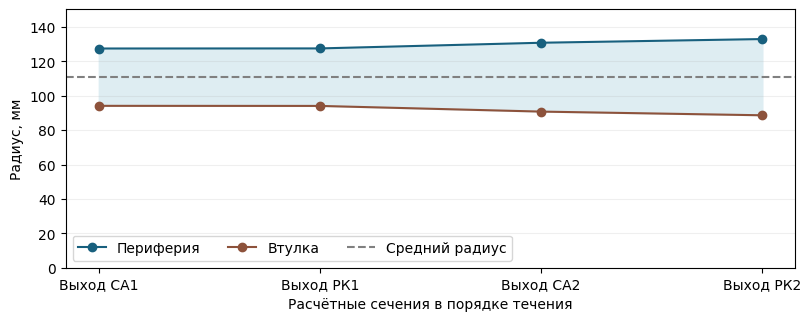

In [15]:
plane_names = ["Выход СА1", "Выход РК1", "Выход СА2", "Выход РК2"]
heights = np.array([first["l1"], first["l2"], second["l1"], second["l2"]])
r_hub = 1000 * (D - heights) / 2
r_tip = 1000 * (D + heights) / 2
fig, ax = plt.subplots(figsize=(8, 3.1), constrained_layout=True)
ax.fill_between(plane_names, r_hub, r_tip, color="#deedf2")
ax.plot(plane_names, r_tip, "o-", color="#18607e", label="Периферия")
ax.plot(plane_names, r_hub, "o-", color="#8d523b", label="Втулка")
ax.axhline(1000*D/2, color="gray", linestyle="--", label="Средний радиус")
ax.set(ylabel="Радиус, мм", xlabel="Расчётные сечения в порядке течения", ylim=(0, 1.13*max(r_tip)))
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="lower left", ncol=3)
plt.show()

### 6.1. Втулка, среднее сечение и периферия

Выбран **закон свободного вихря**. При постоянной осевой скорости и $rc_u=\mathrm{const}$ получаем распределение закрутки по высоте из среднего треугольника. В сочетании с $u=\omega r$ это даёт постоянную по высоте работу Эйлера. На входе и выходе колеса используются свои значения $l$ и $r_mc_{um}$. Сопоставляем одинаковые доли высоты $s=0,\,0{,}5,\,1$ приближённо. Крайние сечения описывают экстраполяцию основного потока к стенкам.

$$r=r_m+(s-0{,}5)l,\quad c_u(r)=c_{um}r_m/r,\quad c_a(r)=c_{am},\quad u(r)=2\pi nr/60,\quad w_u=c_u-u,\quad w_a=c_a.$$

$$T(r)=T_m+\frac{c_{um}^2-c_u(r)^2}{2c_p},\quad p(r)=p_m[T(r)/T_m]^{c_p/R},\quad
M_c=\frac{\sqrt{c_a^2+c_u^2}}{\sqrt{kRT}},\quad M_w=\frac{\sqrt{c_a^2+w_u^2}}{\sqrt{kRT}}.$$

Для оценки реактивности берём идеальные перепады от общего входного полного состояния до локальных статических давлений. Реактивность относится ко всей ступени на данной высоте. В тепловой таблице за РК показана температура основного потока до учёта нагрева от зазора и трения.

$$H(r,p)=c_pT_0^*[1-(p/p_0^*)^{R/c_p}],\quad
\rho_{ст}(s)=1-\frac{H(r_1,p_1)}{H(r_2,p_2)},\quad L_u(s)=u_1c_{1u}-u_2c_{2u}.$$

**Углы.** На входе $\alpha=\operatorname{atan2}(c_a,c_u)$, $\beta=\operatorname{atan2}(c_a,w_u)$. На выходе углы отсчитываются от окружного направления **против вращения**, поэтому второй аргумент меняет знак. В столбцах $c_u,w_u$ в обеих плоскостях сохраняем знак по вращению. Отрицательное $w_u$ означает, что окружная составляющая относительной скорости направлена против вращения.

In [16]:
def radial(st, plane, span):
    if plane == 1:
        l, cum, ca, Tm, pm = st["l1"], st["cu1"], st["ca1"], st["T1"], st["p1"]
    else:
        l, cum, ca, Tm, pm = st["l2"], st["cu2"], st["ca2"], st["T2"], st["p2"]
    r = D/2 + (span - 0.5)*l
    cu = cum * D/(2*r)
    ur = 2 * math.pi * n * r / 60
    wu = cu - ur
    c, w = math.hypot(ca, cu), math.hypot(ca, wu)
    T = Tm + (cum**2 - cu**2)/(2*st["cp"])
    p = pm * (T/Tm)**(st["cp"]/R)
    k = st["cp"] / (st["cp"] - R)
    a = math.sqrt(k * R * T)
    sign = 1 if plane == 1 else -1
    alpha_deg = math.degrees(math.atan2(ca, sign*cu))
    beta_deg = math.degrees(math.atan2(ca, sign*wu))
    return dict(r=r, u=ur, cu=cu, ca=ca, wu=wu, c=c, w=w, T=T, p=p,
                Mc=c/a, Mw=w/a, alpha_deg=alpha_deg, beta_deg=beta_deg)

In [17]:
spans = {"Втулка": 0.0, "Середина": 0.5, "Периферия": 1.0}
vectors, speed_rows, thermal_rows = {}, [], []
for i, st in enumerate(stages, 1):
    for name, span in spans.items():
        inlet = radial(st, 1, span)
        outlet = radial(st, 2, span)
        vectors[i, name] = inlet, outlet
        # Общий множитель cp·T0 в отношении двух идеальных перепадов сокращается.
        exponent = R/st["cp"]
        Hc_rel = 1 - (inlet["p"]/st["p0"])**exponent
        H_rel = 1 - (outlet["p"]/st["p0"])**exponent
        reaction_r = 1 - Hc_rel/H_rel
        Lu_r = inlet["u"]*inlet["cu"] - outlet["u"]*outlet["cu"]
        thermal_rows.append([i, name, inlet["T"], inlet["p"]/1000, outlet["T"], outlet["p"]/1000, reaction_r, Lu_r/1000])
        for edge, v in zip(["Вход", "Выход"], (inlet, outlet)):
            speed_rows.append([i, name, edge, 2000*v["r"], v["u"], v["cu"], v["ca"], v["wu"],
                               v["c"], v["w"], v["alpha_deg"], v["beta_deg"], v["Mc"], v["Mw"], reaction_r])

speeds = pd.DataFrame(speed_rows, columns=["Ст.", "Высота", "РК", "D, мм", "u", "cᵤ", "cₐ=wₐ", "wᵤ",
                                           "c", "w", "α, °", "β, °", "M(c)", "M(w)", "ρст"])
thermal = pd.DataFrame(thermal_rows, columns=["Ст.", "Высота", "T₁, К", "p₁, кПа", "T₂, К", "p₂, кПа", "ρст", "Lᵤ, кДж/кг"])
print("Скорости в м/с, диаметры в мм. Вход РК совпадает с выходом СА.")
display(speeds.set_index(["Ст.", "Высота", "РК"]).round(3), thermal.set_index(["Ст.", "Высота"]).round(3))

Скорости в м/с, диаметры в мм. Вход РК совпадает с выходом СА.


D, мм        u       cᵤ    cₐ=wₐ       wᵤ        c  \
Ст. Высота    РК                                                            
1   Втулка    Вход   188.373  295.896  524.697  144.838  228.801  544.321   
              Выход  188.275  295.742   -0.000  170.778 -295.742  170.778   
    Середина  Вход   221.729  348.290  445.766  144.838   97.475  468.706   
              Выход  221.729  348.290   -0.000  170.778 -348.290  170.778   
    Периферия Вход   255.084  400.684  387.477  144.838  -13.208  413.662   
              Выход  255.182  400.839   -0.000  170.778 -400.839  170.778   
2   Втулка    Вход   181.669  285.365  495.173  184.893  209.808  528.566   
              Выход  177.383  278.632  -26.790  209.308 -305.423  211.015   
    Середина  Вход   221.729  348.290  405.711  184.893   57.421  445.855   
              Выход  221.729  348.290  -21.432  209.308 -369.723  210.402   
    Периферия Вход   261.788  411.215  343.628  184.893  -67.587  390.212   
              Выход  266.074  417.948  -17.860  209.308 -435.809  210.069   

                           w    α, °     β, °   M(c)   M(w)    ρст  
Ст. Высота    РК                                                    
1   Втулка    Вход   270.791  15.432   32.335  0.869  0.432  0.143  
              Выход  341.509  90.000   30.005  0.275  0.550  0.143  
    Середина  Вход   174.584  18.000   56.060  0.737  0.274  0.350  
              Выход  387.906  90.000   26.120  0.275  0.625  0.350  
    Периферия Вход   145.439  20.496   95.210  0.644  0.227  0.481  
              Выход  435.703  90.000   23.077  0.275  0.701  0.481  
2   Втулка    Вход   279.651  20.475   41.388  0.894  0.473  0.199  
              Выход  370.260  82.706   34.423  0.362  0.636  0.199  
    Середина  Вход   193.604  24.500   72.747  0.741  0.322  0.415  
              Выход  424.858  84.154   29.515  0.361  0.729  0.415  
    Периферия Вход   196.859  28.283  110.080  0.642  0.324  0.540  
              Выход  483.466  85.123   25.654  0.361  0.830  0.540

T₁, К  p₁, кПа     T₂, К  p₂, кПа    ρст  Lᵤ, кДж/кг
Ст. Высота                                                            
1   Втулка     1040.415  207.028  1022.423  189.390  0.143     155.256
    Середина   1072.176  234.868  1022.423  189.390  0.350     155.256
    Периферия  1092.315  253.941  1022.423  189.390  0.481     155.256
2   Втулка      919.406  117.302   892.828  101.758  0.199     148.770
    Середина    953.577  136.249   892.937  101.809  0.415     148.770
    Периферия   973.302  148.190   892.997  101.837  0.540     148.770

### 6.2. Треугольники скоростей

По горизонтали откладываем окружную скорость, по вертикали — осевую. Точки $O=(0,0)$, $U=(u,0)$ и $C=(c_u,c_a)$ задают векторы $\overrightarrow{OU}=\vec u$, $\overrightarrow{UC}=\vec w$ и $\overrightarrow{OC}=\vec c$. Для неподвижного СА $U=O$. Масштаб осей одинаков.

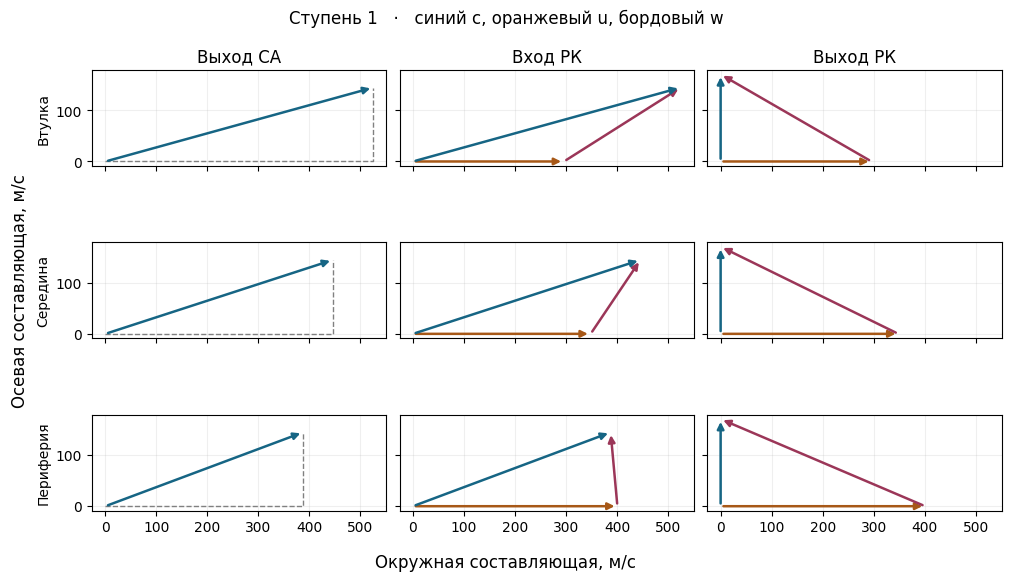

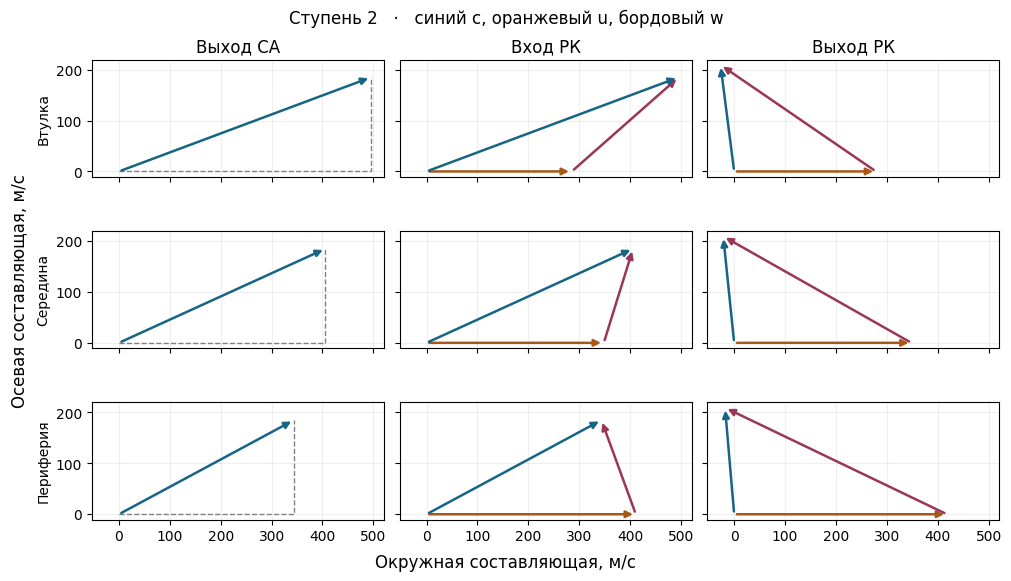

In [18]:
for i in (1, 2):
    fig, axes = plt.subplots(3, 3, figsize=(10, 5.7), sharex=True, sharey=True, constrained_layout=True)
    for row, name in enumerate(spans):
        inlet, outlet = vectors[i, name]
        for col, (ax, v) in enumerate(zip(axes[row], (inlet, inlet, outlet))):
            O, U, C = (0, 0), (v["u"], 0), (v["cu"], v["ca"])
            if col == 0:
                ax.plot([0, C[0], C[0]], [0, 0, C[1]], "--", color="gray", lw=1)
            else:
                ax.annotate("", xy=U, xytext=O, arrowprops=dict(arrowstyle="-|>", lw=1.8, color="#a75817"))
                ax.annotate("", xy=C, xytext=U, arrowprops=dict(arrowstyle="-|>", lw=1.8, color="#9b3658"))
            ax.annotate("", xy=C, xytext=O, arrowprops=dict(arrowstyle="-|>", lw=1.8, color="#166584"))
            ax.update_datalim([O, U, C])
            ax.autoscale_view()
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.2)
            if row == 0:
                ax.set_title(["Выход СА", "Вход РК", "Выход РК"][col])
            if col == 0:
                ax.set_ylabel(name)
    fig.suptitle(f"Ступень {i}   ·   синий c, оранжевый u, бордовый w")
    fig.supxlabel("Окружная составляющая, м/с")
    fig.supylabel("Осевая составляющая, м/с")
    plt.show()

### 6.3. Предварительные профили четырёх венцов

Для СА направление касательных задают пары $(c_a,c_u)$, для РК — $(c_a,w_u)$. Вход в СА1 принят осевым, на вход СА2 передаётся направление за РК1. Углы атаки и отклонения приняты нулевыми. Осевая ширина $b=l_{вых}/2$ для СА и $b=l_{вых}/2{,}5$ для РК. По исходному относительному шагу $t_m/b$ оцениваем число лопаток $Z=\mathrm{round}[\pi D_m/((t_m/b)b)]$. Локальный шаг $t=\pi(r_{вх}+r_{вых})/Z$.

Средняя линия — кубическая кривая Безье. Пусть $\mathbf e_1,\mathbf e_2$ — единичные векторы входной и выходной касательных, $\gamma$ — полусумма их углов **от оси**. Тогда $P_0=(0,0)$, $P_3=b(1,\tan\gamma)$, $P_1=P_0+0{,}4b\mathbf e_1$, $P_2=P_3-0{,}4b\mathbf e_2$.

$$B(t)=(1-t)^3P_0+3(1-t)^2tP_1+3(1-t)t^2P_2+t^3P_3,\qquad 0\le t\le1.$$

Стороны профиля строим смещением средней линии по нормали. При $X=B_x/b$ используем $h(X)=0{,}2969\sqrt X-0{,}126X-0{,}3516X^2+0{,}2843X^3-0{,}1036X^4$. Полутолщина $d=(b/2)(d_{max}/b)h/\max h$. Совмещаем сечения по $B(0{,}5)$. Эти геометрические допущения дают исходные контуры для CAD. Для рабочего профиля потребуются проверка горла, кромок и потерь решётки.

In [19]:
def profile_curve(vin, vout, b):
    """Координаты контура по входной и выходной касательным, осевая ширина b в мм."""
    e1 = np.array(vin) / np.linalg.norm(vin)
    e2 = np.array(vout) / np.linalg.norm(vout)
    angles = [math.atan2(e1[1], e1[0]), math.atan2(e2[1], e2[0])]
    gamma = sum(angles)/2
    P0 = np.array([0.0, 0.0])
    P3 = np.array([b, b*math.tan(gamma)])
    P1 = P0 + 0.4*b*e1
    P2 = P3 - 0.4*b*e2

    # Для каждой точки находим среднюю линию, нормаль и закон толщины.
    mid, normals, thickness_values, X_values = [], [], [], []
    for t in np.linspace(0, 1, 121):
        point = (1-t)**3*P0 + 3*(1-t)**2*t*P1 + 3*(1-t)*t**2*P2 + t**3*P3
        der = 3*((1-t)**2*(P1-P0) + 2*(1-t)*t*(P2-P1) + t**2*(P3-P2))
        normal = np.array([-der[1], der[0]]) / np.linalg.norm(der)
        X = point[0]/b
        h = 0.2969*math.sqrt(X) - 0.126*X - 0.3516*X**2 + 0.2843*X**3 - 0.1036*X**4
        mid.append(point)
        normals.append(normal)
        X_values.append(X)
        thickness_values.append(h)

    # Ставим начало координат в середину и обходим обе стороны профиля.
    center = mid[len(mid)//2]
    h_max = max(thickness_values)
    sideA, sideB = [], []
    for j in range(len(mid)):
        offset = 0.5*b*thickness*thickness_values[j]/h_max
        sideA.append(mid[j] - center + offset*normals[j])
        sideB.append(mid[j] - center - offset*normals[j])
    xy = np.array(sideA + list(reversed(sideB[:-1])))
    X_loop = np.array(X_values + list(reversed(X_values[:-1])))
    return xy, X_loop, np.degrees(angles), math.degrees(gamma)

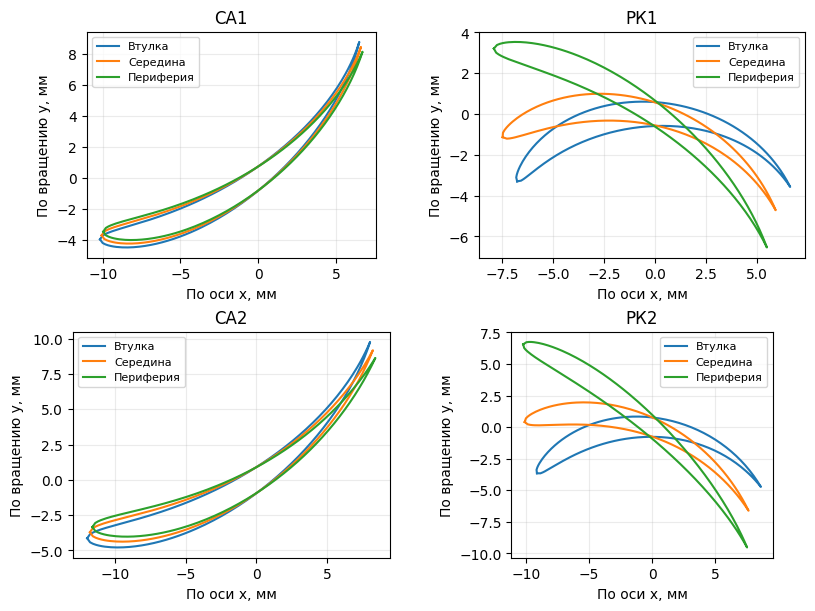

b, мм   Z  Шаг, мм  Установка, °  Вход, °  Выход, °
Ст. Венец Высота                                                         
1   СА    Втулка     16.678  51   11.604        37.284    0.000    74.568
          Середина   16.678  51   13.658        36.000    0.000    72.000
          Периферия  16.678  51   15.713        34.752    0.000    69.504
    РК    Втулка     13.381  63    9.391        -1.165   57.665   -59.995
          Середина   13.381  63   11.057       -14.970   33.940   -63.880
          Периферия  13.381  63   12.723       -36.067   -5.210   -66.923
2   СА    Втулка     20.030  42   13.836        34.762   -0.000    69.525
          Середина   20.030  42   16.585        32.750   -0.000    65.500
          Периферия  20.030  42   19.335        30.859   -0.000    61.717
    РК    Втулка     17.738  48   11.750        -3.483   48.612   -55.577
          Середина   17.738  48   14.512       -21.616   17.253   -60.485
          Периферия  17.738  48   17.274       -42.213  -20.080   -64.346

In [20]:
geom_rows, point_frames = [], []
fig, axes = plt.subplots(2, 2, figsize=(8.3, 6), constrained_layout=True)
for i, st in enumerate(stages, 1):
    for col, kind in enumerate(["СА", "РК"]):
        ax = axes[i-1, col]
        b = 1000 * (st["l1"]/2 if kind == "СА" else st["l2"]/2.5)
        Z = max(1, round(1000*math.pi*D / (pitch_ratio*b)))
        for name in spans:
            inlet, outlet = vectors[i, name]
            if kind == "РК":
                vin, vout = (inlet["ca"], inlet["wu"]), (outlet["ca"], outlet["wu"])
                rin, rout = inlet["r"], outlet["r"]
            else:
                prev = vectors[1, name][1]
                vin = (1, 0) if i == 1 else (prev["ca"], prev["cu"])
                vout = (inlet["ca"], inlet["cu"])
                rin, rout = (inlet["r"] if i == 1 else prev["r"]), inlet["r"]
            xy, X_loop, angles, gamma = profile_curve(vin, vout, b)
            radius = 1000 * (rin + (rout-rin)*X_loop)
            pitch = 1000 * math.pi * (rin+rout) / Z
            geom_rows.append([i, kind, name, b, Z, pitch, gamma, *angles])
            points = pd.DataFrame({"Ст.": i, "Венец": kind, "Высота": name, "Точка": np.arange(len(xy)),
                                   "x, мм": xy[:, 0], "y, мм": xy[:, 1], "r, мм": radius})
            point_frames.append(points)
            ax.plot(xy[:, 0], xy[:, 1], label=name)
        ax.set(title=f"{kind}{i}", xlabel="По оси x, мм", ylabel="По вращению y, мм", aspect="equal")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
plt.show()
geometry = pd.DataFrame(geom_rows, columns=["Ст.", "Венец", "Высота", "b, мм", "Z", "Шаг, мм", "Установка, °", "Вход, °", "Выход, °"])
profile_xyz = pd.concat(point_frames, ignore_index=True)
display(geometry.set_index(["Ст.", "Венец", "Высота"]).round(3))
# Выгрузка всех 12 замкнутых контуров для CAD:
# profile_xyz.to_csv("profiles_12_sections.csv", index=False, sep=";", encoding="utf-8-sig")

<a id="variants"></a>
## Приложение А. Сопоставление и контроль расчёта

Варианты выходного сопла сведены в одну таблицу в [§ 5](#nozzle).

### Энергия, потери и расход

Проверяем сохранение энергии $\Delta h=c_p(T_0^*-T_{вых}^*)-L$ и баланс потерь $\Delta H=H-(h_cT_2/T_1+h_л+c_2^2/2+L_u)$, где $h_c=(\varphi^{-2}-1)c_1^2/2$, $h_л=(\psi^{-2}-1)w_2^2/2$. После добавки $(h_з+h_f)/c_p$ температура возрастает. Если оставить высоту и скорость из треугольника, то расход $G_{гор}=\pi D_m l_2 c_{2a}p_2/(RT_{2,попр})$ слегка расходится с проектным. Это погрешность принятой поправки.

По радиусу независимо проверяем неразрывность интегрированием $G_{инт}=\int_{r_{вт}}^{r_{нар}}2\pi r\,[p(r)/(RT(r))]c_a\,dr$ по 201 точке. Здесь используем температуру основного потока.

В проверке баланса потерь исходная методика приводит потерю СА к выходу ступени через отношение действительных температур. Поэтому в столбце ΔH остаётся небольшая невязка. Уравнение энергии Δh проверяется отдельно.

In [21]:
checks, ring_rows = [], []
for i, st in enumerate(stages, 1):
    hc = (1/st["phi"]**2 - 1) * st["c1"]**2/2
    hl = (1/st["psi"]**2 - 1) * st["w2"]**2/2
    dh = st["cp"]*(st["T0"] - st["Tout_t"]) - st["L"]
    dH = st["H"] - hc*st["T2"]/st["T1"] - hl - st["c2"]**2/2 - st["Lu"]
    Ghot = math.pi * D * st["l2"] * st["ca2"] * st["p2"] / (R*st["Tout"])
    checks.append([i, st["hz"]/1000, st["hf"]/1000, dh, dH, 100*(Ghot/G-1)])
    for plane in (1, 2):
        ring = [radial(st, plane, span) for span in np.linspace(0, 1, 201)]
        radii = np.array([v["r"] for v in ring])
        flux = np.array([2*math.pi*v["r"]*v["p"]*v["ca"]/(R*v["T"]) for v in ring])
        Gint = np.sum(np.diff(radii)*(flux[1:]+flux[:-1])/2)
        ring_rows.append([i, plane, Gint, 100*(Gint/G-1)])
display(pd.DataFrame(checks, columns=["Ст.", "hз, кДж/кг", "hf, кДж/кг", "Δh, Дж/кг", "ΔH, Дж/кг", "ΔG горяч., %"]).set_index("Ст.").round(6))
display(pd.DataFrame(ring_rows, columns=["Ст.", "Плоскость", "Gинт, кг/с", "ΔG по радиусу, %"]).set_index(["Ст.", "Плоскость"]).round(5))

,"hз, кДж/кг","hf, кДж/кг","Δh, Дж/кг","ΔH, Дж/кг","ΔG горяч., %"
Ст.,,,,,
1,3.42452,0.60946,0.0,-33.59824,-0.32613
2,2.75321,0.38727,0.0,-41.93090,-0.29735


Gинт, кг/с  ΔG по радиусу, %
Ст. Плоскость                              
1   1             2.56185          -0.12264
    2             2.56500          -0.00000
2   1             2.56061          -0.17123
    2             2.56498          -0.00092

### Подробные параметры двух ступеней на среднем диаметре

В таблице можно проследить расширение газа от входа в СА до выхода из РК. Удельные перепады, работы и потери приведены в кДж/кг. Для каждой ступени $H^*=c_pT_0^*[1-(p_{вых}^*/p_0^*)^{R/c_p}]$. Сопоставляем четыре определения КПД

$$\eta_u=L_u/H,\qquad \eta_{мощ}=L/H,\qquad \eta_{лоп,ст}=(L+c_2^2/2)/H,\qquad \eta_{ст}^*=L/H^*.$$

In [22]:
detail_rows = []
for st in stages:
    H, L, cp = st["H"], st["L"], st["cp"]
    Hstar = cp*st["T0"] * (1 - (st["pout_t"]/st["p0"])**(R/cp))
    hc = (1/st["phi"]**2 - 1)*st["c1"]**2/2
    hl = (1/st["psi"]**2 - 1)*st["w2"]**2/2
    hv = st["c2"]**2/2
    detail_rows.append({
        "T₀*, К": st["T0"], "p₀*, кПа": st["p0"]/1000, "Реактивность": st["reaction"],
        "Tу, К": st["Ty"], "cp, Дж/(кг·К)": cp, "k": cp/(cp-R),
        "H ступени, кДж/кг": H/1000, "Hс СА, кДж/кг": st["Hc"]/1000, "Hл РК, кДж/кг": st["Hl"]/1000,
        "T₁s, К": st["T1s"], "T₁, К": st["T1"], "p₁, кПа": st["p1"]/1000,
        "v₁, м³/кг": R*st["T1"]/st["p1"], "T₂s, К": st["T1"]-st["Hl"]/cp,
        "T₂, К": st["T2"], "p₂, кПа": st["p2"]/1000, "v₂, м³/кг": R*st["T2"]/st["p2"],
        "hс СА, кДж/кг": hc/1000, "hс приведённая, кДж/кг": hc*st["T2"]/st["T1"]/1000,
        "hл РК, кДж/кг": hl/1000, "c₂²/2, кДж/кг": hv/1000,
        "hз, кДж/кг": st["hz"]/1000, "hf, кДж/кг": st["hf"]/1000, "Nf, кВт": st["Nfr"]/1000,
        "Lᵤ, кДж/кг": st["Lu"]/1000, "L, кДж/кг": L/1000, "T₂ с поправкой, К": st["Tout"],
        "H* ступени, кДж/кг": Hstar/1000, "η на окружности": st["Lu"]/H,
        "η мощностной": L/H, "η лопаточный": (L+hv)/H, "η по полным параметрам": L/Hstar,
    })

display(pd.DataFrame(detail_rows, index=["I ступень", "II ступень"]).T.round(4))

,I ступень,II ступень
"T₀*, К",1163.2665,1037.8612
"p₀*, кПа",340.8999,198.9367
Реактивность,0.3500,0.4150
"Tу, К",1093.1971,965.8237
"cp, Дж/(кг·К)",1205.8657,1179.2694
k,1.3129,1.3222
"H ступени, кДж/кг",183.3642,184.3568
"Hс СА, кДж/кг",119.1868,107.8487
"Hл РК, кДж/кг",64.6447,77.0877
"T₁s, К",1064.4273,946.4074


### Раскрытие канала и предварительная механическая оценка

При симметричном раскрытии полный угол $\Gamma=2\arctan[(l_{вых}-l_{вх})/(2b)]$. Для РК берём $b=l_{вых}/2{,}5$, для СА2 $b=l_{вых}/2$. Из эмпирического критерия исходного листа $\sigma_{оц}=k_n A_{пред} n^2$, $n_{пред}=\sqrt{[\sigma]/(k_n A_{пред})}$ при $A_{пред}$ в м² и $n$ в об/мин. Это предварительная оценка напряжения.

In [23]:
opening = []
for name, lin, lout, aspect in [("РК1", first["l1"], first["l2"], 2.5),
                                ("СА2", first["l2"], second["l1"], 2.0),
                                ("РК2", second["l1"], second["l2"], 2.5)]:
    opening.append([name, math.degrees(2*math.atan((lout-lin)/(2*lout/aspect)))])
display(pd.DataFrame(opening, columns=["Венец", "Полный угол раскрытия, °"]).set_index("Венец").round(3))
stress = kn * A_pre * n**2
n_limit = math.sqrt(stress_limit/(kn*A_pre))
print(f"Оценка напряжения {stress:.2f} МПа при принятом пределе {stress_limit:g} МПа. Предельная частота {n_limit:.0f} об/мин.")

,"Полный угол раскрытия, °"
Венец,
РК1,0.422
СА2,18.727
РК2,13.779


Оценка напряжения 189.05 МПа при принятом пределе 320 МПа. Предельная частота 39031 об/мин.


### Варианты степени сжатия и эмпирическая оценка массы

Сравниваем предварительные циклы для одинакового задания по мощности. Для каждого $\pi_к^*$ используем расход до проектного округления, уже найденный в § 2. Числа по рассчитанным ступеням проектного варианта приведены в § 4.4. Удельный расход $C_e=3{,}6\cdot10^6 G_т/N_{зад}$ в кг/(кВт·ч), эффективный КПД $\eta_e=N_{зад}/(G_т Q_н)$.

$$K_T=1+0{,}0002(T_4^*-1200),\quad
M_{осн}=66G_в^{0{,}74}[(\pi_к^*)^{0{,}286}-1]^{0{,}16}K_TK_{сх}K_{рес}.$$

$$x_N=N_{зад}/n,\quad M_{ред}=5+78x_N-2{,}38x_N^2,\quad M_{дв}=M_{осн}+M_{ред},\quad
M_{т,взл}=60\tau_{мин}G_т,\quad J=M_{дв}+M_{т,взл}.$$

В выражение для редуктора подставляются Вт и об/мин, как в исходном листе. Размерности эмпирических коэффициентов требуют подтверждения. Столбцы масс служат для сопоставления вариантов этой модели.

,"Gв, кг/с","Gт, кг/с","Gг, кг/с","Ce, кг/(кВт·ч)",ηe,"LСТ, кДж/кг","Mосн, кг","Mред, кг","Mдв, кг","Mт взл., кг","J, кг"
πк,,,,,,,,,,,
7.0,2.6183,0.0659,2.6659,0.3161,0.2648,285.6036,107.6077,467.5,575.1077,19.7568,594.8645
8.0,2.5654,0.0628,2.6103,0.3016,0.2776,291.6862,107.4841,467.5,574.9841,18.8497,593.8338
9.0,2.5361,0.0606,2.5790,0.2908,0.2879,295.2267,107.8389,467.5,575.3389,18.1749,593.5138
10.0,2.5230,0.0589,2.5642,0.2825,0.2963,296.9309,108.5213,467.5,576.0213,17.6576,593.6789
11.0,2.5214,0.0575,2.5612,0.2760,0.3033,297.2718,109.4414,467.5,576.9414,17.2527,594.1941


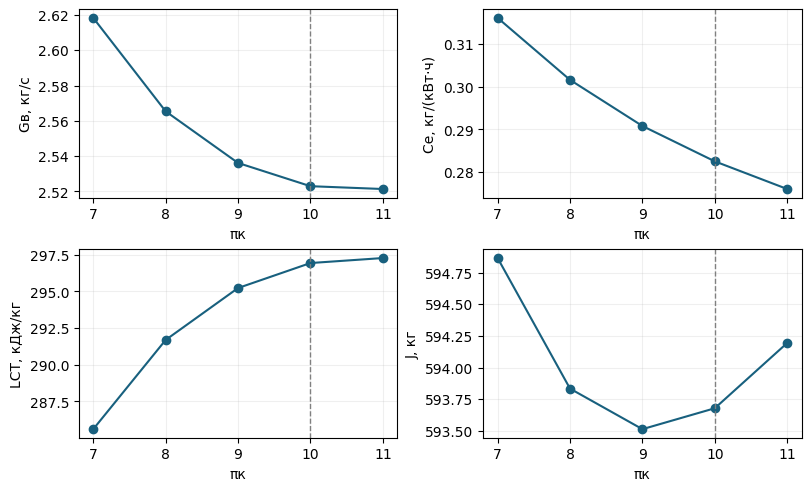

In [24]:
xN = N_req / n
Mgear = 5 + 78*xN - 2.38*xN**2
KT = 1 + 0.0002*(T4t-1200)
variant_rows = []
for pi_k, case in cycle_data.items():
    L_v = case["Lpt"]
    G_v = case["G_pre"]
    Gair_v = G_v/case["mg"]
    Gfuel_v = case["f"]*Gair_v
    Ce = 3.6e6*Gfuel_v/N_req
    eta_e = N_req/(Gfuel_v*Qfuel)
    Mcore = 66*Gair_v**0.74*(pi_k**0.286-1)**0.16*KT*Kscheme*Kresource
    Mengine = Mcore + Mgear
    Mfuel = 60*takeoff_min*Gfuel_v
    J = Mengine + Mfuel
    variant_rows.append([pi_k, Gair_v, Gfuel_v, G_v, Ce, eta_e, L_v/1000, Mcore, Mgear, Mengine, Mfuel, J])
variants = pd.DataFrame(variant_rows, columns=["πк", "Gв, кг/с", "Gт, кг/с", "Gг, кг/с", "Ce, кг/(кВт·ч)",
    "ηe", "LСТ, кДж/кг", "Mосн, кг", "Mред, кг", "Mдв, кг", "Mт взл., кг", "J, кг"]).set_index("πк").sort_index()
display(variants.round(4))
fig, axes = plt.subplots(2, 2, figsize=(8, 4.8), constrained_layout=True)
for ax, key in zip(axes.flat, ["Gв, кг/с", "Ce, кг/(кВт·ч)", "LСТ, кДж/кг", "J, кг"]):
    ax.plot(variants.index, variants[key], "o-", color="#18607e")
    ax.axvline(pi_design, ls="--", color="gray", lw=1)
    ax.set(xlabel="πк", ylabel=key, xticks=variants.index)
    ax.grid(alpha=0.2)
plt.show()

<a id="properties"></a>
## Приложение Б. Полиномы теплоёмкости

Температура в К, результат в Дж/(кг·К), для газа $\alpha>0{,}2$. Введём $A=0{,}0025T-0{,}875$, $B=0{,}000025T^2-0{,}0275T+6{,}5625$, $C=0{,}001176T-0{,}88235$, $E=0{,}0000055556T^2-0{,}013056T+6{,}67$.

| Величина | Нижняя ветвь | Верхняя ветвь |
|---|---|---|
| $c_{pв}/4187$ | $0{,}2407+0{,}0193A+0{,}002B$ | $0{,}26+0{,}032C-0{,}00374E$ |
| $c_{pг}/4187$ | $0{,}2407+0{,}0174/\alpha+(0{,}0193+0{,}0093/\alpha)A+(0{,}002-0{,}001056/(\alpha-0{,}2))B$ | $0{,}26+0{,}0267/\alpha+(0{,}032+0{,}0133/\alpha)C-[0{,}00374+0{,}0094/(\alpha^2+10)]E$ |
| $c_{pm,в}/4187$ | $0{,}236+1{,}2\cdot10^{-5}(T-70)$ | $0{,}218+2{,}2\cdot10^{-5}(T+450)$ |
| $c_{pm,г}/4187$ | $0{,}236+(2{,}25/\alpha+1{,}2)10^{-5}(T-70)$ | $0{,}218+(1{,}25/\alpha+2{,}2)10^{-5}(T+450)$ |

Для истинных теплоёмкостей правая ветвь начинается с 750 К, для средних — с 700 К. Множитель 4187 соответствует пересчёту исходных коэффициентов теплоёмкости в Дж/(кг·К).

**Основа расчёта.** Исходный лист «С_учетом_охлаждения_многоступенч.xmcd» и перенесённый из него расчёт Jupyter. Для ступеней и профилирования в исходной работе использовано пособие В. Е. Михальцева и В. Д. Молякова «Теория и проектирование газовой турбины», с. 68–74 и 88–93. Для сверки исходного варианта до округления расхода использованы расчётная записка «Свободная турбина. Полный расчёт» и таблица скоростей и диаметров для выпуска 210,41 м/с.

<a id="symbols"></a>
## Словарь переменных

Слева указано точное имя Python, по которому можно искать через Ctrl+F, далее обозначение, смысл и единица, используемая внутри расчёта. Индекс **t** в именах температур и давлений соответствует звёздочке. **I** и **II** означают номер ступени, суффикс **_v** — вариант степени сжатия. Числа 1 и 2 внутри имени ступенчатой величины означают плоскость до и после РК. Доля охлаждения и реактивность безразмерны. Плотность газа обозначена отдельно от реактивности.

### Цикл и режим

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `N_req` | $N_{зад}$ | Заданная мощность после редуктора | Вт |
| `pi_design` | $\pi_к^*$ | Проектная степень повышения полного давления компрессора | — |
| `n` | $n$ | Частота вращения свободной турбины | об/мин |
| `Ta` | $T_н$ | Температура наружного воздуха | К |
| `pa` | $p_н$ | Статическое давление атмосферы | Па |
| `R` | $R$ | Удельная газовая постоянная модели | Дж/(кг·К) |
| `sigma_in` | $\sigma_{вх}$ | Сохранение полного давления во входном устройстве | — |
| `eta_poly` | $\eta_{пол}$ | Политропический КПД компрессора | — |
| `sigma_burn` | $\sigma_{кс}$ | Сохранение полного давления в камере сгорания | — |
| `eta_burn` | $\eta_г$ | Коэффициент полноты сгорания | — |
| `Qfuel` | $Q_н$ | Низшая теплота сгорания топлива | Дж/кг |
| `l0` | $l_0$ | Стехиометрическая масса воздуха на 1 кг топлива | кг/кг |
| `leak` | $g_{ут}$ | Безвозвратные утечки в долях расхода воздуха компрессора | — |
| `cool` | $g_{охл}$ | Отбор на охлаждение в долях расхода воздуха компрессора | — |
| `T4t` | $T_4^*$ | Полная температура смеси в горле СА ТВД | К |
| `eta_hpt` | $\eta_{ТВД}$ | КПД ТВД по полным параметрам | — |
| `eta_mech` | $\eta_м$ | Механический КПД в балансе каждого вала | — |
| `eta_gear` | $\eta_р$ | КПД редуктора | — |

### Предварительная СТ и выпуск

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `eta_pre` | $\eta_{лоп,пред}$ | Лопаточный КПД в предварительном цикле | — |
| `c_pre` | $c_{пред}$ | Заданная скорость за СТ в предварительном расчёте | м/с |
| `rp` | $r_p$ | Отношение статических давлений атмосферы и газа за РК2 | — |
| `sigma_nozzle` | $\sigma_с$ | Отношение полных давлений на срезе и за РК2 | — |
| `height_ratio` | $\lambda$ | Отношение выходной высоты лопатки к среднему диаметру | — |
| `y0` | $y_0$ | Отношение скоростей для оценки числа ступеней | — |
| `mu` | $\mu$ | Коэффициент использования выходной скорости | — |
| `c_mean` | $\bar c_2$ | Принятая средняя выходная скорость за ступенью для оценки числа ступеней | м/с |

### Венцы и профили

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `reaction_I` | $\rho_I$ | Заданная реактивность I ступени на среднем радиусе | — |
| `reaction_II` | $\rho_{II}$ | Заданная реактивность II ступени на среднем радиусе | — |
| `angle1_I` | $\alpha_{1,I}$ | Угол абсолютной скорости за СА1 от направления вращения | ° |
| `angle1_II` | $\alpha_{1,II}$ | Угол абсолютной скорости за СА2 от направления вращения | ° |
| `angle2_I` | $\alpha_{2,I}$ | Угол абсолютной скорости за РК1 от направления против вращения | ° |
| `phi_I` | $\varphi_I$ | Коэффициент скорости соплового аппарата I ступени | — |
| `phi_II` | $\varphi_{II}$ | Коэффициент скорости соплового аппарата II ступени | — |
| `psi_I` | $\psi_I$ | Коэффициент скорости РК I ступени, подбор в исходной точке | — |
| `psi_II` | $\psi_{II}$ | Коэффициент скорости РК II ступени, подбор в исходной точке | — |
| `gap` | $\delta$ | Радиальный зазор обоих РК | м |
| `thickness` | $d_{max}/b$ | Относительная максимальная толщина профиля | — |
| `pitch_ratio` | $t_m/b$ | Заданный относительный шаг на среднем радиусе | — |

### Параметры дополнительных вариантов

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `c_target` | $c_{ц}$ | Заданная скорость для обратного расчёта сопла | м/с |
| `stress_limit` | $[\sigma]$ | Принятое предельное напряжение в эмпирической оценке | МПа |
| `kn` | $k_n$ | Коэффициент эмпирической формулы напряжения | МПа/[м²·(об/мин)²] |
| `takeoff_min` | $\tau_{мин}$ | Продолжительность взлётного режима для оценки массы топлива | мин |
| `Kscheme` | $K_{сх}$ | Поправка на схему двигателя в формуле массы | — |
| `Kresource` | $K_{рес}$ | Поправка на ресурс двигателя в формуле массы | — |

### Цикл и предварительные размеры

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `T` | $T$ | Температура в функциях свойств, локальная статическая температура в радиальном расчёте | К |
| `alpha` | $\alpha$ | Коэффициент избытка воздуха смеси после возврата охлаждения | — |
| `value` | $c_p/4187$ | Промежуточное значение полинома истинной теплоёмкости до перевода единиц | численное |
| `cp` | $c_p$ | Рабочее значение удельной изобарной теплоёмкости соответствующего участка | Дж/(кг·К) |
| `k` | $k$ | Показатель адиабаты участка | — |
| `pi_k` | $\pi_к^*$ | Степень сжатия текущего варианта цикла | — |
| `e` | $e$ | Изоэнтропический показатель степени (k−1)/k для компрессора | — |
| `eta_k` | $\eta_к$ | Адиабатический КПД компрессора | — |
| `Tk`, `pk` | $T_к^*,\ p_к^*$ | Полные температура и давление за компрессором | К, Па |
| `Lk` | $L_к$ | Работа компрессора на 1 кг воздуха | Дж/кг |
| `hmix` | $h_г$ | Энтальпия смеси при заданных 1440 К в исходном варианте | Дж/кг |
| `f` | $f$ | Масса топлива на 1 кг воздуха компрессора | кг/кг |
| `mg` | $m_г$ | Масса газа после смешения на 1 кг воздуха компрессора | кг/кг |
| `Lh` | $L_{ТВД}$ | Полезная работа ТВД на 1 кг газа | Дж/кг |
| `base` | $1-L_{ТВД}/(\eta_{ТВД}c_pT_4^*)$ | Температурное отношение для изоэнтропического расширения в ТВД | — |
| `Tin`, `pin` | $T_{СТ,вх}^*,\ p_{СТ,вх}^*$ | Полные температура и давление перед свободной турбиной | К, Па |
| `cp_hpt`, `cp_pt` | $c_{p,ТВД},\ c_{p,СТ}$ | Принятые теплоёмкости ТВД и предварительного расчёта СТ | Дж/(кг·К) |
| `p5` | $p_5$ | Заданное статическое давление за РК2 | Па |
| `Hpt`, `Lpt` | $H_{СТ},\ L_{СТ}$ | Располагаемый перепад СТ до статики и предварительная полезная работа на 1 кг газа | Дж/кг |
| `Tpre` | $T_{5,пред}$ | Предварительная статическая температура за СТ | К |
| `G`, `Gair`, `Gfuel` | $G_г,\ G_в,\ G_т$ | Массовые расходы газа через СТ, воздуха на входе и топлива | кг/с |
| `A_pre` | $A_{пред}$ | Кольцевая площадь на выходе турбины по предварительному расчёту | м² |
| `D`, `l_exit` | $D_m,\ l_{вых}$ | Средний диаметр и проектная высота газового канала за РК2 | м |
| `u` | $u$ | Окружная скорость на среднем радиусе. В записи радиального сечения поле u содержит локальное значение | м/с |
| `q`, `c0` | $q,\ c_0$ | Скорость с учётом коэффициента использования и адиабатическая скорость всей СТ | м/с |
| `z_est` | $z_{оц}$ | Предварительная оценка числа ступеней | — |
| `H_first` | $H_I$ | Располагаемый перепад I ступени | Дж/кг |
| `G_pre` | $G_{г,пред}$ | Предварительный массовый расход газа до принятия проектного значения | кг/с |
| `h_air` | $h_{в.к}$ | Удельная энтальпия воздуха после компрессора относительно 288 К | Дж/кг |
| `A`, `B`, `C`, `E` | $A,B,C,E$ | Температурные члены полиномов истинной теплоёмкости (приложение Б) | — |

### Ступень, мощность и выходное сопло

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `T0`, `p0` | $T_0^*,\ p_0^*$ | Входные полные температура и давление конкретной ступени | К, Па |
| `phi`, `psi` | $\varphi,\ \psi$ | Коэффициенты скорости СА и РК текущей ступени, переданные из исходных данных | — |
| `reaction`, `angle1` | $\rho_{ст},\ \alpha_1$ | Реактивность на среднем радиусе и выходной угол СА расчётной ступени | —, ° |
| `H`, `Hc`, `Hl` | $H,\ H_c,\ H_л$ | Располагаемые удельные перепады ступени, соплового аппарата и рабочего колеса по принятой методике | Дж/кг |
| `Ty`, `cp_new` | $T_y,\ c_{p,нов}$ | Условная температура ступени и уточнённая при ней теплоёмкость | К, Дж/(кг·К) |
| `c1`, `ca1`, `cu1` | $c_1,\ c_{1a},\ c_{1u}$ | Модуль абсолютной скорости за СА и её осевая и окружная составляющие | м/с |
| `T1s`, `T1`, `p1` | $T_{1s},\ T_1,\ p_1$ | Изоэнтропическая и действительная статические температуры и статическое давление за СА | К, К, Па |
| `l1`, `l2` | $l_1,\ l_2$ | Высоты газового канала на входе и выходе РК | м |
| `w1`, `w2` | $w_1,\ w_2$ | Относительные скорости на входе и выходе РК | м/с |
| `T2`, `p2` | $T_2,\ p_2$ | Статические температура и давление за РК до поправки температуры на дополнительные потери | К, Па |
| `c2`, `ca2`, `cu2` | $c_2,\ c_{2a},\ c_{2u}$ | Модуль абсолютной скорости за РК, её осевая и окружная составляющие. Ось u направлена по вращению | м/с |
| `a2`, `disc` | $\alpha_2,\ w_2^2-u^2\sin^2\alpha_2$ | Выходной угол РК1 в радианах и подкоренное выражение при построении треугольника | рад, м²/с² |
| `Lu`, `L` | $L_u,\ L$ | Работа на окружности и полезная работа ступени с учётом зазора и трения | Дж/кг |
| `hz`, `hf` | $h_з,\ h_f$ | Удельные потери в зазоре и на трение диска | Дж/кг |
| `rho_disk`, `Nfr` | $\bar\rho,\ N_f$ | Средняя плотность для модели дискового трения и мощность трения | кг/м³, Вт |
| `Tout`, `Tout_t`, `pout_t` | $T_{2,попр},\ T_{вых}^*,\ p_{вых}^*$ | Исправленная статическая температура, полные температура и давление за колесом | К, К, Па |
| `Lsum`, `Htt` | $L_\Sigma,\ H_{т}^*$ | Суммарная полезная работа и теплоперепад всей СТ по полным давлениям | Дж/кг |
| `Nshaft`, `error_N` | $N_{вал},\ \varepsilon_N$ | Мощность после редуктора и отклонение от задания со знаком | Вт, % |
| `eta_blade`, `eta_tt` | $\eta_{лоп},\ \eta_{т}^*$ | Общий лопаточный КПД и КПД свободной турбины по полным параметрам | — |
| `T5t`, `p5t` | $T_5^*,\ p_5^*$ | Полные температура и давление за РК2 на входе в сопло | К, Па |
| `cp9`, `k9` | $c_{p,9},\ k_9$ | Принятые теплоёмкость и показатель адиабаты в выпуске | Дж/(кг·К), — |
| `sigma`, `pa` | $\sigma_с,\ p_н$ | Сохранение полного давления данного варианта выпуска и внешнее противодавление | —, Па |
| `p9t`, `pcrit`, `p9` | $p_9^*,\ p_{кр},\ p_9$ | Полное давление у среза, критическое статическое давление и действительное статическое давление среза | Па |
| `T9`, `rho9` | $T_9,\ \rho_9$ | Статические температура и плотность на срезе | К, кг/м³ |
| `c9`, `a9`, `M9` | $c_9,\ a_9,\ M_9$ | Осевая скорость струи, местная скорость звука и число Маха среза | м/с, м/с, — |
| `A9`, `F9` | $A_9,\ F_9$ | Эффективная площадь среза и валовая тяга выпускной струи | м², Н |
| `Ttarget`, `sigma_target` | $T_{ц},\ \sigma_{ц}$ | Статическая температура и требуемое сохранение полного давления для заданной скорости среза | К, — |
| `margin_kW` | $N_{вал}-N_{зад}$ | Запас рассчитанной мощности после редуктора | кВт |
| `c_exit` | $c_{9}$ | Скорость в проектном выходном сопле | м/с |

### Параметры по высоте и геометрия

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `heights`, `r_hub`, `r_tip` | $l,\ r_{вт},\ r_{нар}$ | Высоты четырёх плоскостей и соответствующие втулочные и наружные радиусы на графике | м, мм, мм |
| `span`, `l`, `r` | $s,\ l,\ r$ | Относительная высота от втулки к периферии, местная полная высота канала и радиус рассматриваемой точки | —, м, м |
| `cum`, `Tm`, `pm` | $c_{um},\ T_m,\ p_m$ | Окружная составляющая и статические параметры среднего радиуса данной плоскости | м/с, К, Па |
| `ur`, `cu`, `ca`, `wu` | $u(r),\ c_u,\ c_a=w_a,\ w_u$ | Локальная окружная скорость лопатки и проекции скоростей газа | м/с |
| `c`, `w`, `a` | $c,\ w,\ a$ | Модули абсолютной и относительной скоростей, скорость звука по локальной температуре | м/с |
| `p` | $p$ | Локальное статическое давление | Па |
| `Mc`, `Mw` | $M_c,\ M_w$ | Числа Маха в абсолютном и относительном движении | — |
| `alpha_deg`, `beta_deg` | $\alpha,\ \beta$ | Углы абсолютной и относительной скоростей в принятом окружном отсчёте | ° |
| `sign` | $\pm1$ | Знак для отсчёта угла. +1 на входе РК, −1 на выходе | — |
| `reaction_r`, `Lu_r` | $\rho_{ст}(s),\ L_u(s)$ | Оценка реактивности ступени и удельная работа Эйлера на данной высоте | —, Дж/кг |
| `O`, `U`, `C` | $O,\ U,\ C$ | Точки начала и концов векторов на диаграмме скоростей, компоненты окружная и осевая | м/с |
| `vin`, `vout` | $\mathbf v_{вх},\ \mathbf v_{вых}$ | Направления по парам осевая и окружная компоненты. Для СА1 осевой вход задан единичным направлением | м/с или направление |
| `rin`, `rout`, `radius` | $r_{вх},\ r_{вых},\ r(X)$ | Радиусы сечения на входе и выходе венца, массив радиусов точек контура для CAD | м, м, мм |
| `b`, `Z`, `pitch` | $b,\ Z,\ t_{шаг}$ | Осевая ширина венца, число лопаток, шаг по окружности на данной высоте | мм, шт., мм |
| `e1`, `e2`, `angles` | $\mathbf e_1,\ \mathbf e_2,\ (\theta_1,\theta_2)$ | Единичные касательные на входе и выходе и пара их углов от оси. Функция считает в радианах, возвращает углы в градусах | —, —, рад → ° |
| `gamma` | $\gamma$ | Угол установки как полусумма углов касательных. Из функции возвращается в градусах | рад → ° |
| `P0`, `P1`, `P2`, `P3` | $P_0,\ P_1,\ P_2,\ P_3$ | Четыре опорные точки средней линии Безье в развёртке (ось, окружность) | мм |
| `t`, `mid`, `der` | $t,\ B(t),\ B'(t)$ | Параметр кривой, координаты средней линии и её производная по t | —, мм, мм |
| `normal`, `X`, `h` | $\mathbf n,\ X,\ h(X)$ | Единичная нормаль, относительная осевая координата и функция распределения толщины | — |
| `offset`, `sideA`, `sideB` | $d,\ B_+,\ B_-$ | Полутолщина по нормали и координаты двух сторон профиля | мм |
| `xy`, `X_loop` | $x,y,\ X$ | Пары локальных координат замкнутого контура и соответствующие относительные осевые координаты | мм, — |
| `exponent`, `Hc_rel`, `H_rel` | $R/c_p, H_c/(c_pT_0^*), H/(c_pT_0^*)$ | Показатель степени и относительные перепады в расчёте реактивности по высоте | — |
| `point`, `center` | $B(t), B(0{,}5)$ | Точка средней линии и начало координат сечения | мм |
| `X_values`, `thickness_values`, `h_max`, `normals` | $X, h(X), \max h, \mathbf n$ | Координаты, значения распределения толщины, его максимум и векторы нормалей | — |

### Проверки и дополнительные варианты

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `hc`, `hl` | $h_c,\ h_л$ | Удельные профильные потери СА и РК. В коде большие Hc и Hl обозначают перепады | Дж/кг |
| `Hstar`, `hv` | $H^*,\ c_2^2/2$ | Располагаемый полный перепад отдельной ступени и кинетическая энергия выхода на единицу массы | Дж/кг |
| `dh`, `dH` | $\Delta h,\ \Delta H$ | Невязка уравнения энергии и баланса потерь ступени | Дж/кг |
| `Ghot`, `Gint` | $G_{гор},\ G_{инт}$ | Расход за РК после температурной поправки и интегральный расход по кольцу | кг/с |
| `radii`, `flux` | $r,\ 2\pi r\rho c_a$ | Узлы радиальной сетки и подынтегральный массовый расход на единицу радиуса | м, кг/(с·м) |
| `lin`, `lout`, `aspect` | $l_{вх},\ l_{вых},\ l_{вых}/b$ | Входная и выходная высоты венца, отношение высоты к осевой ширине | м, м, — |
| `stress`, `n_limit` | $\sigma_{оц},\ n_{пред}$ | Предварительные оценки напряжения и предельной частоты вращения | МПа, об/мин |
| `L_v`, `G_v`, `Gair_v`, `Gfuel_v` | $L_{СТ},\ G_г,\ G_в,\ G_т$ | Предварительная работа СТ и расходы газа, воздуха и топлива в текущем варианте | Дж/кг, кг/с |
| `Ce`, `eta_e` | $C_e,\ \eta_e$ | Удельный расход топлива на мощность после редуктора и эффективный КПД цикла | кг/(кВт·ч), — |
| `KT`, `xN` | $K_T,\ x_N$ | Температурная поправка на массу и аргумент модели массы редуктора | —, Вт/(об/мин) |
| `Mcore`, `Mgear`, `Mengine` | $M_{осн},\ M_{ред},\ M_{дв}$ | Эмпирические оценки массы основной части двигателя, редуктора и их суммы | кг |
| `Mfuel`, `J` | $M_{т,взл},\ J$ | Масса топлива за время взлёта и суммарный массовый показатель | кг |

### Функции и вспомогательные переменные

| Имя в Python | Что содержит или выполняет |
|---|---|
| `cp_true`, `cp_mean` | Истинная и средняя удельные теплоёмкости, Дж/(кг·К). Аргументы — температура и коэффициент избытка воздуха. |
| `radial`, `profile_curve` | Параметры потока в одной точке по высоте и построение геометрического контура лопатки. |
| `pi_values`, `cycle_data`, `case`, `design` | Рассматриваемые степени сжатия, значения по всем циклам, текущий вариант и выбранный проектный вариант. |
| `stages`, `first`, `second`, `st` | Список обеих ступеней, результаты I, II и текущей ступени. |
| `stage_rows`, `detail_rows` | Строки сводной и подробной таблиц ступеней. |
| `nozzle_cases`, `nozzle_row`, `nozzle_rows` | Сценарии по потерям, одна строка и все строки сравнительной таблицы сопла. |
| `spans`, `vectors`, `j` | Три высоты, пары входных и выходных состояний и номер точки профиля. |
| `inlet`, `outlet`, `prev`, `v`, `ring` | Местные состояния до и после колеса, состояние за РК1 для входа СА2, одна точка и набор точек радиальной сетки. |
| `plane`, `plane_names`, `i`, `name`, `edge`, `kind` | Номер плоскости РК (1 или 2), подписи сечений, номер ступени, подпись текущей высоты или варианта, сторона РК, тип венца СА/РК. |
| `speed_rows`, `thermal_rows`, `speeds`, `thermal` | Строки и таблицы скоростей, углов, реактивности и статических параметров по высоте. |
| `profile_curve`, `points`, `point_frames`, `profile_xyz` | Расчёт контура, точки одного сечения, набор таблиц и общая таблица координат для CAD. |
| `geom_rows`, `geometry`, `checks`, `ring_rows`, `opening` | Строки и таблица геометрии, проверки энергии, радиального расхода и раскрытия канала. |
| `variant_rows`, `variants` | Строки и итоговая таблица вариантов степени сжатия. |
| `fig`, `ax`, `axes`, `row`, `col`, `key` | Рисунок, панель, массив панелей, индексы строки и столбца, имя столбца таблицы для графика. |
| `math`, `np`, `pd`, `plt`, `display`, `_` | Математика, численные массивы, таблицы, графики, вывод в Jupyter и пропускаемое значение или счётчик повторений. |

[К расчёту сопла](#nozzle) · [К началу расчёта](#inputs)